# Notebook 2 extension: does the QAM gap persist with longer training?

This extends the existing two-dimensional obstacle task to three seeds and
300 Actor optimizer updates per method. The environment, offline data recipe,
frozen Base, deployment sampler, Lean Adjoint, Adam, and TD implementation are
inherited unchanged from `02_qam_point_obstacle.py`.

Ordinary QAM uses `-beta * grad_a Q_critic` as the terminal adjoint. The
privileged reference branch uses a direct current-policy MC score gradient
with 8192 simulator trajectories per endpoint. Both branches still perform
one TD update per Actor update. A GPU accelerates only Actor forward calls;
the independent environment transitions use the original NumPy simulator.
No new PAGR method is introduced.

The new user-approved protocol checks gradient precision, not scalar Q as a
veto. Independent MC uses the original NumPy simulator and separate IID
trajectories. Scalar Q disagreement is retained as a diagnostic. Snapshot
checks include actual training endpoints; they do not certify every point.

The old N=10 smoke and original audit FAIL are separate historical artifacts.
A first GPU-table extension paused at seed 59001, N=50 because a near-goal
gradient failed independent MC. Table and quadrature refinement did not cure
the bias. The MC extension restarts Actor training at N=0 with unchanged
thresholds. Seed 59001 was seen in numerical development, so conclusions are
explicitly exploratory.

## What changed, and what did not?

The environment has position $p_k\in[0,1]^2$ and action $a_k\in\mathbb R^2$:

$$p_{k+1}=p_k+\Delta\tanh(a_k)+\sigma\xi_k,\qquad \xi_k\sim\mathcal N(0,I).$$

The goal gives +1, segment collision / leaving the square gives -1, and
timeout gives 0. Subsequent actions come from the **frozen current Actor**,
not a best-action maximization or a reference Critic. For a fixed first
state/action, let $G$ be the discounted return of that continuation. Then

$$\nabla_a Q^\pi(k,p,a)=\frac{\Delta(1-\tanh^2(a))}{\sigma}
      \odot\mathbb E[\xi_k G].$$

The implementation uses the unbiased sample covariance, which removes a
constant return baseline without changing this expectation:

$$\widehat{\nabla_a Q^\pi}=\frac{\Delta(1-\tanh^2(a))}{\sigma}
 \odot\frac{1}{M-1}\sum_{m=1}^{M}(\xi^{(m)}-\bar\xi)(G^{(m)}-\bar G),
 \quad M=8192.$$

Ordinary QAM supplies $-\beta\nabla_a Q_{\rm critic}$ to the lean-adjoint
terminal condition; Reference-QAM supplies $-\beta\widehat{\nabla_a Q^\pi}$.
The rest of the matching objective and the Actor optimizer are unchanged.
Both branches update a TD Critic, but the reference branch does **not** use
that Critic to supply its Actor's terminal gradient. It is a privileged
diagnostic, not a simulator-free replacement algorithm.

This experiment can test a finite-update performance gap. It cannot by
itself establish that Q values are already accurate, that the effect is
caused only by adjoint amplification, or that a cheap new algorithm wins.
Success/return also do not equal the full KL/energy-regularized AM objective;
this extension does not claim to have measured improvement in that objective.

In [1]:
import json
import os
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if not (ROOT/'configs/point_long_training_mc.json').exists():
    ROOT = ROOT.parent
protocol = json.loads((ROOT/'configs/point_long_training_mc.json').read_text())
display(pd.DataFrame([dict(seeds=protocol['seeds'], actor_updates=protocol['actor_updates'],
                          curve_updates=protocol['curve_updates'],
                          audit_updates=protocol['audit_updates'],
                          final_episodes=protocol['final_episodes'])]))

,seeds,actor_updates,curve_updates,audit_updates,final_episodes
0,"[59001, 59002, 59003]",300,"[0, 10, 25, 50, 100, 150, 200, 300]","[0, 50, 150, 300]",4096


Training implementation: `scripts/run_point_long_training.py`.
Local MC reference: `MonteCarloReference` in the training script.
Historical accelerated table: `scripts/point_reference_accelerated.py`.
Analysis: `scripts/analyze_point_long_training.py`.

Launch explicitly from the repository root (GPU environment):

```bash
.venv/bin/python -u scripts/run_point_long_training.py \
  --protocol configs/point_long_training_mc.json \
  --output runs/02-qam-point-obstacle-long-mc-v2-20261029 --device cuda
```

Checkpoints preserve Actor, Critic, target, both Adam states, training RNG,
and source/protocol hashes. Repeating the command resumes the same protocol;
a changed scientific source or configuration is rejected.

Comparison uses fixed checkpoints, independent final evaluation, paired test
noise, and all three seeds. Extra reference compute is reported separately.
Success thresholds 60/70/80 percent are fixed before observing the curves.

In [2]:
run = Path(os.environ.get('PAGR_LONG_RUN',
           ROOT/'runs/02-qam-point-obstacle-long-mc-v2-20261029'))
if (run/'protocol.json').exists():
    display(Markdown((run/'report.md').read_text()) if (run/'report.md').exists()
            else Markdown('Training has started; the aggregate report is pending.'))
else:
    display(Markdown('No local result directory yet. Training can run on Ubuntu; '
                     'set `PAGR_LONG_RUN` to a synced result directory to inspect it.'))

# Obstacle QAM: training-budget extension

Status: complete.
All required snapshot gradient checks passed: True.

The user approved a new gradient-focused admission protocol. Scalar Q–MC
discrepancy is reported but does not veto a gradient comparison. Historical
audit FAIL records are unchanged. This is a numerical privileged-reference
comparison, not an exact oracle or a new PAGR algorithm.

Three predeclared seeds; 300 Actor updates each; the same TD update counts,
initialization and training RNG streams within each pair.
The current-policy gradient is estimated locally from 8192 IID simulator rollouts per training endpoint; no value table or learned reference Critic is used.
Extra reference computation is not equalized with Ordinary QAM.

Success and discounted return are environment-performance metrics. They
are not the KL/energy-regularized AM extraction objective; this extension
does not establish an improvement in that full control objective.

## Observed success gaps

| Actor updates | Mean reference − ordinary (pp) | Seed SD (pp) | Seeds |
|---:|---:|---:|---:|
| 0 | 0.000 | 0.000 | 3 |
| 10 | 13.574 | 1.824 | 3 |
| 25 | 9.082 | 2.018 | 3 |
| 50 | 12.044 | 1.333 | 3 |
| 100 | 12.793 | 2.817 | 3 |
| 150 | 13.542 | 1.681 | 3 |
| 200 | 14.648 | 0.775 | 3 |
| 300 | 15.072 | 1.080 | 3 |

![All learning curves](learning-curves.png)

![Paired success gap](success-gap.png)

## Independent final evaluation

| Method | Success (%) | Collision / bounds (%) | Discounted return |
|---|---:|---:|---:|
| Ordinary QAM | 51.123 ± 1.311 | 48.869 ± 1.322 | -0.035 ± 0.021 |
| Reference-gradient QAM | 65.796 ± 0.680 | 34.204 ± 0.680 | 0.210 ± 0.012 |

Values are training-seed mean ± SD, not episode-level uncertainty.

| Seed | Success gap (pp) | Return gap | Failures repaired | Successes lost |
|---:|---:|---:|---:|---:|
| 59001 | 12.769 | 0.21387 | 562 | 39 |
| 59002 | 16.699 | 0.28057 | 789 | 105 |
| 59003 | 14.551 | 0.24280 | 640 | 44 |

Mean final success gap: 14.673 percentage points.
Within-seed evaluation SE is not training-seed uncertainty. Three seeds
remain a small exploratory sample; no universal advantage is inferred.

## Compute accounting

| Method | Updates recorded | Update wall time (s) | Extra simulator continuations |
|---|---:|---:|---:|
| Ordinary QAM | 900 | 4.88 | 0 |
| Reference-gradient QAM | 900 | 1334.72 | 471859200 |

These timings include TD and Actor/reference computation, but exclude
shared pretraining, evaluation, checkpoint serialization and precision audits.
Simulator continuations start at sampled environment times, so they have
different remaining horizons; they are not full episodes from the initial state.

Snapshot validation samples eight frozen geometry cases and eight actual
training endpoints at N=0/50/150/300 per branch, with two independent
8192-rollout MC streams per point and an independent 32768-rollout reference.
It is sampled validation, not proof of accuracy everywhere or at every update.

Fixed success thresholds are 60%, 70%, 80%; first observed crossings are
checkpoint-grid measurements, not interpolated exact crossing times.
All curves, gaps, threshold crossings, final paired episodes and audit
tables are saved alongside this report.

The table-based v1 run paused at seed 59001 reference N=50 after a
gradient mismatch near the goal. Refining the table/quadrature did not
remove it. This v2 run restarts Actor updates from N=0 with a direct MC
reference, retaining the same seeds, initialization and acceptance
thresholds. Stochastic-reference comparison SE combines both independent
estimator variances. Seed 59001 was seen during numerical development;
this is exploratory evidence, not an untouched confirmatory seed set.

The saved scalar `q_mc_z_rms` diagnostic normalizes by audit MC SE only;
unlike the gradient gate it does not include the stochastic training-reference
variance. Do not interpret it as a calibrated two-estimator significance test.
No scalar-Q diagnostic determines training admission in this protocol.


**success-gap-aggregate.csv**

,N,mean,std,count
0,0,0.000000,0.000000,3
1,10,13.574219,1.824369,3
2,25,9.082031,2.017967,3
3,50,12.044271,1.333047,3
4,100,12.792969,2.816837,3
5,150,13.541667,1.681087,3
6,200,14.648438,0.775122,3
7,300,15.071615,1.080121,3


**final-independent.csv**

,seed,method,N,success_rate,collision_rate,timeout_rate,discounted_return,mean_success_length,episodes
0,59001,learned,300,0.522949,0.476807,0.000244,-0.016354,13.327264,4096
1,59001,reference,300,0.650635,0.349365,0.000000,0.197517,13.387617,4096
2,59002,learned,300,0.497070,0.502930,0.000000,-0.058227,13.442534,4096
3,59002,reference,300,0.664062,0.335938,0.000000,0.222347,13.506250,4096
4,59003,learned,300,0.513672,0.486328,0.000000,-0.031721,13.352186,4096
5,59003,reference,300,0.659180,0.340820,0.000000,0.211078,13.425185,4096


**sample-efficiency.csv**

,seed,method,success_threshold,first_observed_update,reached,max_observed_update,success_auc,normalized_success_auc
0,59001,learned,0.6,NaN,False,300,152.187500,0.507292
1,59001,learned,0.7,NaN,False,300,152.187500,0.507292
2,59001,learned,0.8,NaN,False,300,152.187500,0.507292
3,59001,reference,0.6,10.0,True,300,188.193359,0.627311
4,59001,reference,0.7,NaN,False,300,188.193359,0.627311
5,59001,reference,0.8,NaN,False,300,188.193359,0.627311
6,59002,learned,0.6,NaN,False,300,147.556152,0.491854
7,59002,learned,0.7,NaN,False,300,147.556152,0.491854
8,59002,learned,0.8,NaN,False,300,147.556152,0.491854
9,59002,reference,0.6,10.0,True,300,189.123535,0.630412


**gradient-audits.csv**

,seed,method,N,passed,reference_mc_rms,mc_se_rms,gradient_z_rms,gradient_z_max,q_mc_z_rms,critic_reference_rms,higher_precision_drift_rms,training_reference_se_rms,estimator
0,59001,learned,0,True,0.021988,0.015367,1.210587,2.938009,3.103165,0.476467,0.024604,0.021837,iid-monte-carlo-score
1,59001,learned,150,True,0.024419,0.015763,0.993627,2.202451,1.917154,0.448048,0.024832,0.022194,iid-monte-carlo-score
2,59001,learned,300,True,0.025439,0.016065,0.942370,2.670688,1.359701,0.456333,0.015246,0.022695,iid-monte-carlo-score
3,59001,learned,50,True,0.023328,0.016770,0.800796,1.781461,1.696937,0.469949,0.025142,0.023655,iid-monte-carlo-score
4,59001,reference,150,True,0.020008,0.015447,0.981165,2.631665,1.844545,0.451999,0.023895,0.021960,iid-monte-carlo-score
5,59001,reference,300,True,0.022227,0.015100,0.999265,2.800036,1.586015,0.462692,0.016940,0.021296,iid-monte-carlo-score
6,59001,reference,50,True,0.029557,0.016081,1.092681,2.114471,1.640010,0.465246,0.019368,0.022785,iid-monte-carlo-score
7,59002,learned,0,True,0.024492,0.018241,1.007297,2.209823,1.673154,0.478292,0.026010,0.025822,iid-monte-carlo-score
8,59002,learned,150,True,0.028778,0.018537,0.960805,2.085697,2.053403,0.490054,0.022207,0.026282,iid-monte-carlo-score
9,59002,learned,300,True,0.027011,0.016815,1.107824,2.287336,2.262926,0.456072,0.027005,0.023948,iid-monte-carlo-score


**training-cost.csv**

,seed,method,updates,update_seconds,reference_seconds,extra_simulator_continuations
0,59001,learned,300,1.618941,0.000000,0
1,59001,reference,300,443.739690,441.917562,157286400
2,59002,learned,300,1.627675,0.000000,0
3,59002,reference,300,443.714955,441.876027,157286400
4,59003,learned,300,1.633918,0.000000,0
5,59003,reference,300,447.265077,445.434034,157286400


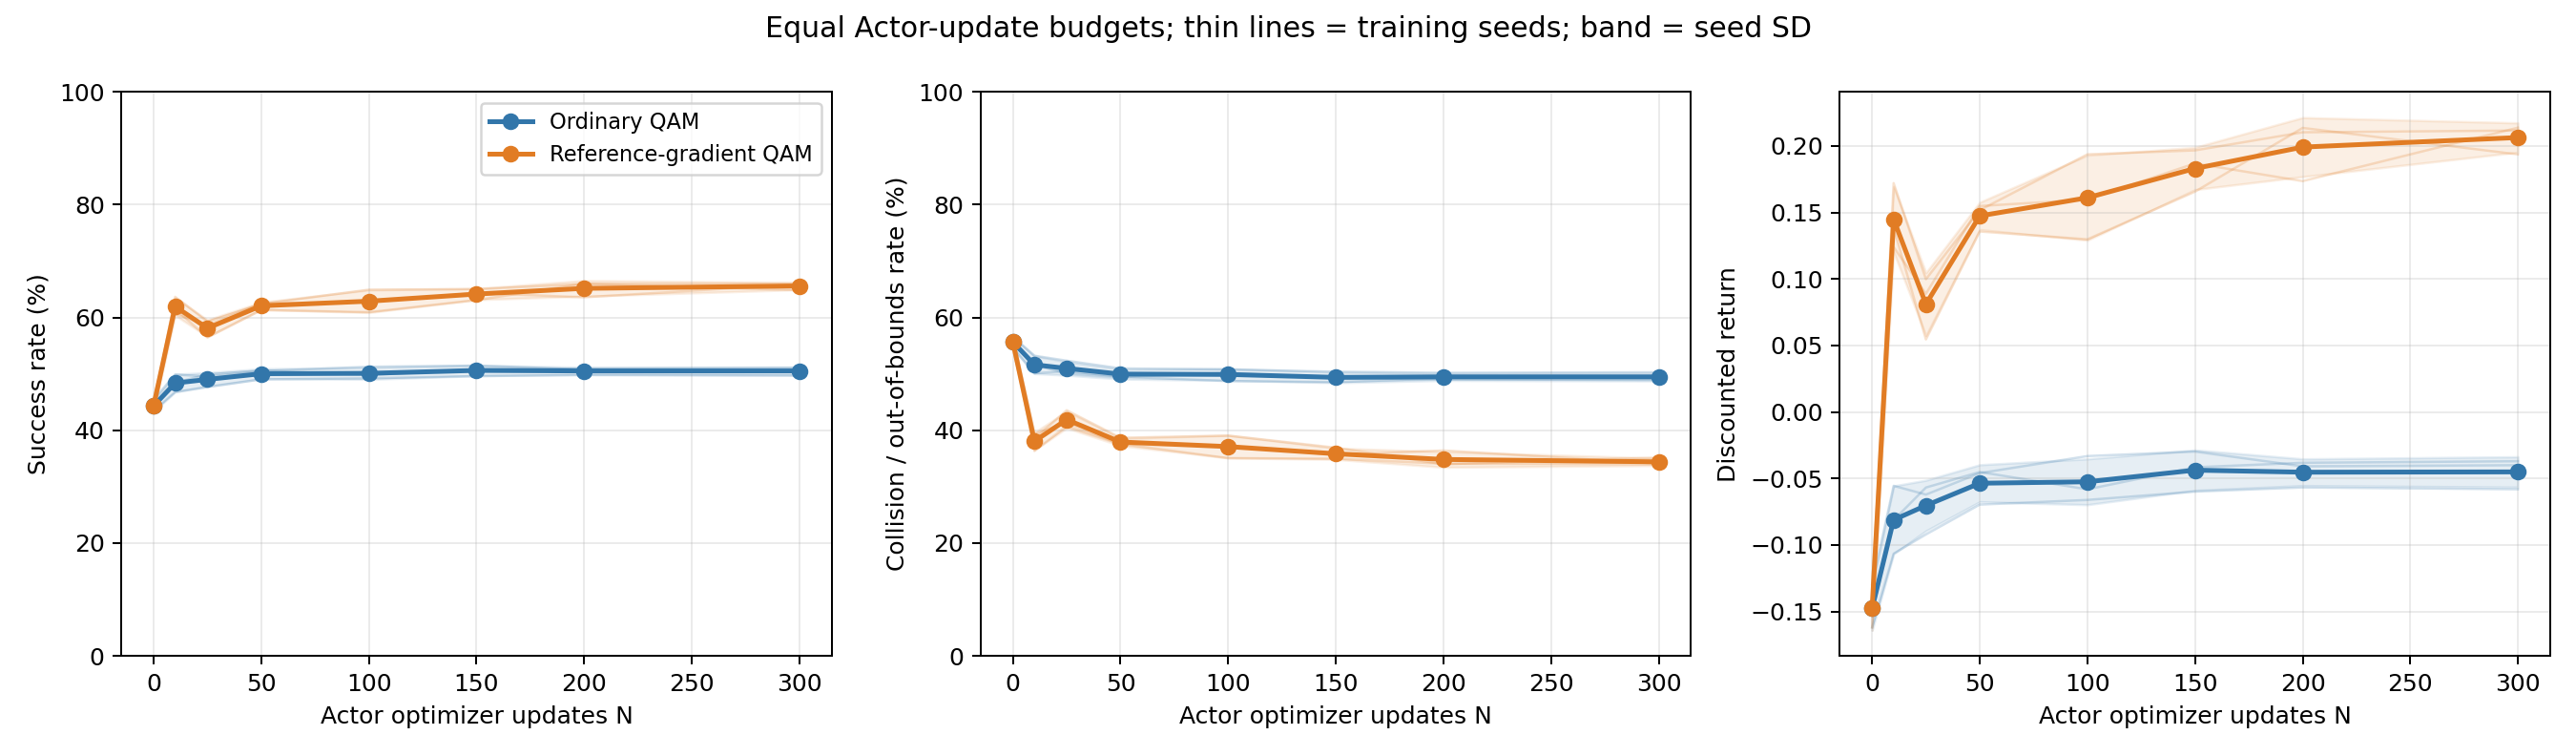

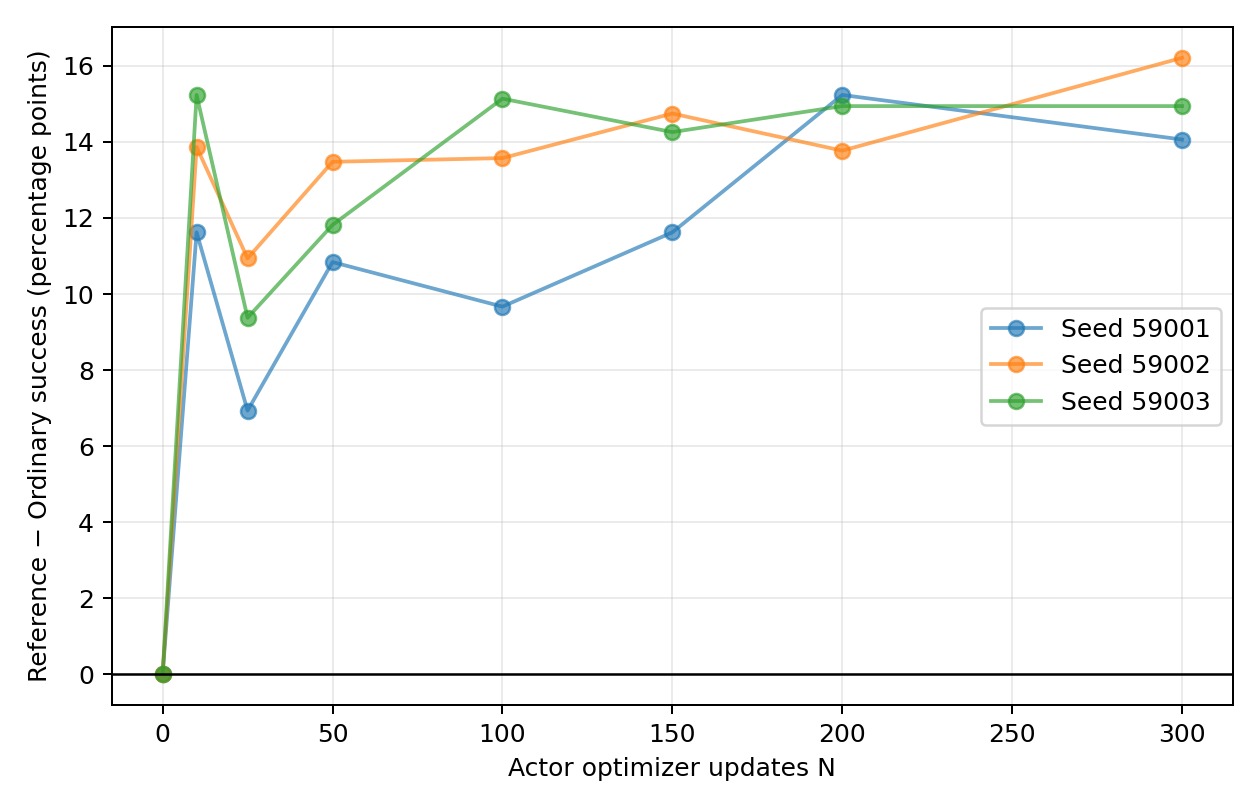

In [3]:
for filename in ('success-gap-aggregate.csv', 'final-independent.csv',
                 'sample-efficiency.csv', 'gradient-audits.csv', 'training-cost.csv'):
    if (run/filename).exists():
        display(Markdown(f'**{filename}**'))
        display(pd.read_csv(run/filename))
for filename in ('learning-curves.png', 'success-gap.png'):
    if (run/filename).exists():
        display(Image(filename=str(run/filename)))

Interpret early and late gaps separately. An early advantage followed by
convergence can support an update-efficiency benefit. A persistent advantage
can support a finite-budget performance benefit. Neither pattern should be
assumed in advance, and three training seeds remain exploratory evidence.